# Proyecto Iris: Exploración y Vinculación del Dataset LSA-T
Análisis exhaustivo del dataset LSA-T. El objetivo de este cuaderno es establecer la lógica para:
1. Cargar y filtrar los metadatos (etiquetas y traducciones).
2. Leer los tensores de keypoints desde el archivo HDF5.
3. Vincular correctamente el video, los metadatos temporales y las coordenadas anatómicas de la persona correcta (`infered_signer`).

In [12]:
# Instalación de dependencias (descomentar si es necesario)
# !pip install pandas h5py matplotlib opencv-python numpy

import pandas as pd
import h5py
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from pathlib import Path

DATA_DIR = Path("../../data/lsa-t")
META_PATH = DATA_DIR / "meta.csv"
JOINTS_PATH = DATA_DIR / "keypoints.h5"  # Ajustado al nombre real de tu archivo
CLIPS_DIR = DATA_DIR / "clips"

if not META_PATH.exists():
    print(f"Error: Aún no se encuentra el archivo en {META_PATH.resolve()}")
else:
    print(f"Rutas configuradas correctamente. Leyendo desde: {DATA_DIR.resolve()}")

Rutas configuradas correctamente. Leyendo desde: C:\Users\juana\OneDrive\Escritorio\paginitas\ProyectoIris\data\lsa-t


## 1. Análisis de Metadatos (`meta.csv`)
El archivo `meta.csv` es el índice central. Contiene 8.459 registros con las traducciones (`label`) y datos cruciales para la extracción: `signers_amount` y `infered_signer`.

,id,label,video,playlist,start,end,duration,splits,prev_delta,post_delta,signers_amount,infered_signer,infered_signer_confidence,movement_per_signer
0,noticias-en-lengua-de-senas-argentina-resumen-...,"para dejar en el camino tanto inglés, para que...",noticias-en-lengua-de-senas-argentina-resumen-...,resumen_semanal,3.90,14.64,9.698,"[('para dejar en el camino tanto inglés, para ...",NaN,0.08,18,signer_0,0.655516,"[887.7418858923028, 0.0, 0.0, 0.0, 0.0, 0.0, 0..."
1,noticias-en-lengua-de-senas-argentina-resumen-...,mientras trabajábamos para brindarte toda la ...,noticias-en-lengua-de-senas-argentina-resumen-...,resumen_semanal,14.72,37.12,26.420,[(' mientras trabajábamos para brindarte toda ...,0.08,0.06,2,signer_1,0.918192,"[87.20544617999867, 978.774125717577]"
2,noticias-en-lengua-de-senas-argentina-resumen-...,será recordado por siempre. este programa es u...,noticias-en-lengua-de-senas-argentina-resumen-...,resumen_semanal,37.18,43.54,6.360,[('será recordado por siempre. este programa e...,0.06,33.27,2,signer_1,0.902476,"[86.94047806316571, 804.5370448144228]"
3,noticias-en-lengua-de-senas-argentina-resumen-...,buenas noches. bienvenidos a cn sordos argent...,noticias-en-lengua-de-senas-argentina-resumen-...,resumen_semanal,76.81,82.66,4.730,[(' buenas noches. bienvenidos a cn sordos arg...,33.27,0.18,2,signer_1,0.844739,"[200.19024111633087, 1089.1848828644502]"
4,noticias-en-lengua-de-senas-argentina-resumen-...,mi nombre es lucía.,noticias-en-lengua-de-senas-argentina-resumen-...,resumen_semanal,82.84,84.75,1.910,"[('mi nombre es lucía.', 82.84, 84.75)]",0.18,32.00,2,signer_0,0.671262,"[814.6965620154058, 398.9830419710953]"


Total de clips: 8459
Columnas disponibles: ['id', 'label', 'video', 'playlist', 'start', 'end', 'duration', 'splits', 'prev_delta', 'post_delta', 'signers_amount', 'infered_signer', 'infered_signer_confidence', 'movement_per_signer']

Distribución de cantidad de personas (signers) por clip:
signers_amount
2     4413
0     2888
3      676
4      238
5      108
6       50
7       20
8       17
9       10
10       7
11       6
13       6
22       3
15       3
12       2
16       2
14       2
17       2
18       1
20       1
30       1
36       1
24       1
32       1
Name: count, dtype: int64


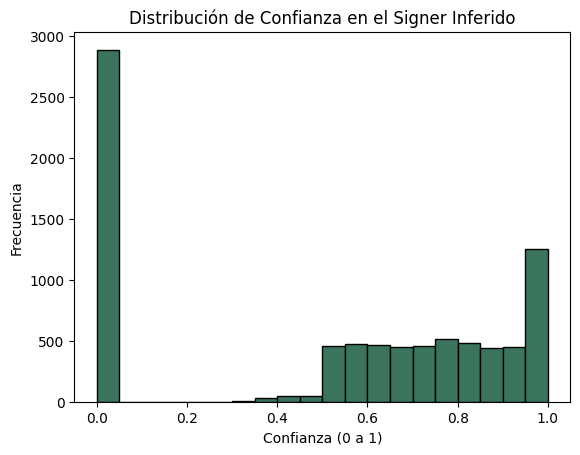

In [13]:
# Cargar metadatos
df_meta = pd.read_csv(META_PATH)

# Mostrar la estructura principal
display(df_meta.head())

print(f"Total de clips: {len(df_meta)}")
print(f"Columnas disponibles: {list(df_meta.columns)}")

# Estadísticas sobre la cantidad de signers por video
print("\nDistribución de cantidad de personas (signers) por clip:")
print(df_meta['signers_amount'].value_counts())

# Distribución de la confianza del signer inferido
plt.hist(df_meta['infered_signer_confidence'].dropna(), bins=20, color='#3A745D', edgecolor='black')
plt.title('Distribución de Confianza en el Signer Inferido')
plt.xlabel('Confianza (0 a 1)')
plt.ylabel('Frecuencia')
plt.show()

## 2. Lectura y Estructura de Keypoints (`joints.h5`)
Los keypoints están guardados en formato HDF5 (Hierarchical Data Format). 
La jerarquía interna es: `id_del_clip` -> `signer_i` -> `Matriz [x, y, z, confidence]`.
Es vital usar la columna `infered_signer` del CSV para saber qué grupo `signer_i` leer cuando hay más de una persona en el video.

In [14]:
# Exploración de la estructura del HDF5 (Corregida)
with h5py.File(JOINTS_PATH, 'r') as h5_file:
    # Obtener los primeros 3 IDs de clips como ejemplo
    sample_clip_ids = list(h5_file.keys())[:3]
    print(f"IDs de muestra en el HDF5: {sample_clip_ids}\n")
    
    for clip_id in sample_clip_ids:
        print(f"Clip ID: {clip_id}")
        signers = list(h5_file[clip_id].keys())
        print(f"  Signers detectados en este clip: {signers}")
        
        for signer in signers:
            signer_group = h5_file[clip_id][signer]
            
            # El signer es un grupo, obtenemos sus claves internas
            componentes = list(signer_group.keys())
            print(f"  -> Componentes anatómicos para {signer}: {componentes}")
            
            for comp in componentes:
                item = signer_group[comp]
                
                # Verificamos si es un Dataset (matriz) para imprimir su shape
                if isinstance(item, h5py.Dataset):
                    print(f"     * Tensor '{comp}': {item.shape}")
                else:
                    # Si resulta ser otro grupo anidado
                    print(f"     * Grupo '{comp}': Contiene {list(item.keys())}")
        print("-" * 40)

IDs de muestra en el HDF5: ['agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_10.mp4', 'agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_101.mp4', 'agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_104.mp4']

Clip ID: agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_10.mp4
  Signers detectados en este clip: ['signer_0']
  -> Componentes anatómicos para signer_0: ['boxes', 'keypoints']
     * Tensor 'boxes': (225, 4)
     * Tensor 'keypoints': (225, 2172)
----------------------------------------
Clip ID: agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_101.mp4
  Signers detectados en este clip: ['signer_0']
  -> Componentes anatómicos para signer_0: ['boxes', 'keypoints']
     * Tensor 'boxes': (539, 4)
     * Tensor 'keypoints': (539, 2172)
----------------------------------------
Clip ID: agua-

## 3. Función de Vinculación (Metadata ↔ HDF5 ↔ Video)
Esta función aislará la lógica que luego irá al backend (FastAPI o pipeline de ML en PyTorch). Recibe un `clip_id` y devuelve su traducción, los keypoints normalizados de la persona correcta, y verifica si el archivo de video existe.

In [15]:
def get_lsa_clip_data(clip_id: str, df: pd.DataFrame, h5_path: Path, clips_dir: Path):
    """
    Extrae toda la información sincronizada de un clip específico.
    """
    # 1. Obtener metadatos
    meta_row = df[df['id'] == clip_id]
    if meta_row.empty:
        raise ValueError(f"Clip {clip_id} no encontrado en metadatos.")
    
    meta_row = meta_row.iloc[0]
    translation = meta_row['label']
    signer_id = meta_row['infered_signer']
    
    keypoints = None
    boxes = None
    
    # 2. Obtener Keypoints del HDF5
    try:
        with h5py.File(h5_path, 'r') as h5_file:
            # Validamos si el clip existe en el h5 (algunos del CSV podrían no estar procesados)
            if clip_id not in h5_file:
                print(f"Advertencia: Clip {clip_id} no existe en HDF5.")
            else:
                # Si el signer es nulo (NaN), tomamos la primera persona detectada por defecto
                if pd.isna(signer_id) or str(signer_id) == 'nan':
                    signer_id = list(h5_file[clip_id].keys())[0]
                
                if signer_id in h5_file[clip_id]:
                    # Extraemos matrices específicas
                    keypoints = h5_file[clip_id][signer_id]['keypoints'][:]
                    boxes = h5_file[clip_id][signer_id]['boxes'][:]
                else:
                    print(f"Advertencia: Signer {signer_id} no encontrado en {clip_id}")
                    
    except Exception as e:
        print(f"Error procesando HDF5 para {clip_id}: {e}")
        
    # 3. Verificar Video
    video_path = clips_dir / f"{clip_id}.mp4"
    video_exists = video_path.exists()
    
    return {
        "clip_id": clip_id,
        "translation": translation,
        "target_signer": signer_id,
        "keypoints_shape": keypoints.shape if keypoints is not None else None,
        "boxes_shape": boxes.shape if boxes is not None else None,
        "video_path": str(video_path),
        "video_exists": video_exists
    }

# Prueba de concepto (Usamos un ID que vimos en la celda anterior que SÍ existe)
sample_id = 'agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_10'
data = get_lsa_clip_data(sample_id, df_meta, JOINTS_PATH, CLIPS_DIR)

print(f"Traducción: {data['translation']}")
print(f"Signer Objetivo: {data['target_signer']}")
print(f"Forma del tensor Keypoints: {data['keypoints_shape']}")
print(f"Forma del tensor Boxes: {data['boxes_shape']}")
print(f"Video disponible en disco: {data['video_exists']}")

Advertencia: Clip agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_10 no existe en HDF5.
Traducción: ¿qué es el agua? el agua es un recurso natural.
Signer Objetivo: nan
Forma del tensor Keypoints: None
Forma del tensor Boxes: None
Video disponible en disco: False


## 4. Visualización Básica de Video usando OpenCV
Dado que el objetivo final es un MVP con Computer Vision, validamos que los `.mp4` (1920x1080 a 30 FPS) puedan procesarse frame a frame, preparando el terreno para el posterior dataloader de PyTorch.

In [16]:
def inspect_video(video_path: str, max_frames=5):
    """
    Abre el video con OpenCV y extrae dimensiones y frames de prueba.
    """
    if not os.path.exists(video_path):
        print(f"Archivo no encontrado: {video_path}")
        return
        
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"Resolución: {width}x{height} | FPS: {fps} | Total Frames: {total_frames}")
    
    frames_read = 0
    while cap.isOpened() and frames_read < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        # OpenCV lee en BGR, convertimos a RGB para matplotlib
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        plt.figure(figsize=(4, 3))
        plt.imshow(frame_rgb)
        plt.axis('off')
        plt.title(f"Frame {frames_read}")
        plt.show()
        
        frames_read += 1
        
    cap.release()

In [17]:
inspect_video(data['video_path'])

Archivo no encontrado: ..\..\data\lsa-t\clips\agua-como-tomar-conciencia-sobre-su-cuidado-episodio-3-en-lengua-de-senas-argentina-lsa_10.mp4


In [18]:
import os
from pathlib import Path

# Ajustar ruta relativa
CLIPS_DIR = Path("../../data/lsa-t/clips")

if not CLIPS_DIR.exists():
    print(f"❌ La carpeta {CLIPS_DIR.resolve()} no existe. ¡Falta descomprimir clips.7z!")
else:
    archivos = list(CLIPS_DIR.glob('*.mp4'))
    print(f"✅ Carpeta encontrada. Contiene {len(archivos)} videos .mp4")
    if len(archivos) > 0:
        print(f"Ejemplo del primer video: {archivos[0].name}")

❌ La carpeta C:\Users\juana\OneDrive\Escritorio\paginitas\ProyectoIris\data\lsa-t\clips no existe. ¡Falta descomprimir clips.7z!
